# Manufacturing Capacity & Ramp-up Optimization
## Apple GSM-aligned, 16-week synthetic case

**Case periods:** W1–W16 (Jan 5 – Apr 26, 2026). **Source:** the bundled SQLite database. It is **not proprietary Apple data**.

### Decision question
Can the supplier meet increasing customer orders by rebalancing output, adding overtime, improving performance, or investing in a new machine? What are the delivery and cost trade-offs?

### Important conceptual distinction
1. **Actual**: production, receipts, inventory movement and shipments as recorded.
2. **As-is LP**: retrospective *optimized counterfactual* using the same installed machines; it can differ from actual production.
3. **Intervention scenarios**: policies that begin in W9 and are evaluated with realized 16-week data and perfect hindsight.
4. **Stress testing**: scenarios with explicitly assumed variation, not a statistical forecast.


In [1]:
from pathlib import Path
import sys, json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if not (ROOT / "python" / "run_project.py").exists():
    ROOT = ROOT.parent
assert (ROOT / "python" / "run_project.py").exists(), "Open notebook from project folder or notebooks folder"
sys.path.insert(0, str(ROOT / "python"))
from run_project import load_data, prepare_tables, optimize_16w
pd.set_option('display.max_columns', 20)
print('Project root:', ROOT)

Project root: /mnt/data/apple_gsm_manufacturing_project


## 1. Data audit and raw evidence
We have actual **machine × date × shift × product** production records, as well as orders, shipments, material receipts and WIP snapshots. A single machine shift can contain a P01 row and a P02 row: time must be deduplicated before computing operating capacity.

In [2]:
tables = load_data()
for n in ['fact_production','fact_customer_order','fact_shipment','fact_inventory_snapshot','dim_machine']:
    print(f'{n:30s}',len(tables[n]))
data = prepare_tables(tables)
print('Finished units W16:',int(data['stage_week'].query('week_id == 16 and stage_id == 4').good_units.iloc[0]))
display(data['stage_week'].query('week_id==16')[['stage_id','input_units','good_units','yield_pct','operating_minutes','observed_load_pct']].round(2))

fact_production                6160
fact_customer_order            32
fact_shipment                  222
fact_inventory_snapshot        224
dim_machine                    15
Finished units W16: 52780


,stage_id,input_units,good_units,yield_pct,operating_minutes,observed_load_pct
60,1,64662,63881,98.79,16850,94.59
61,2,56443,55412,98.17,22308,91.87
62,3,55412,53375,96.32,22079,78.64
63,4,53375,52780,98.89,22245,66.91


## 2. Reconcile actual order fulfillment, FG and WIP
**Demand ≠ finished production ≠ shipments.** The initial finished inventory is 4,200 units. In the case data, all recorded shipments are no later than their due dates but some W16 order quantity remains unfulfilled.

The supplied `fact_inventory_snapshot.finished_goods_units` is **zero throughout the period**, while a positive FG ledger can be reconstructed from production, opening stock, and shipments. This is a data-quality discrepancy; the notebook uses the balanced flow ledger for FG.

In [3]:
a=data['actual_service']; w=data['actual_wip']
print('Demand:',int(a.demand_units.sum()))
print('Shipped:',int(a.shipped_units.sum()))
print('End unmet:',int(a.query('week_id==16').end_unfulfilled_order_units.sum()))
print('Finished output:',int(data['stage_week'].query('stage_id==4').good_units.sum()))
print('Initial FG:',int(tables['fact_initial_inventory'].opening_finished_goods_units.sum()))
print('End WIP before Grinding:',int(w.query('week_id==16 and after_stage_id==1').ending_wip_units.sum()))
print('WIP max reconciliation error:',w.reconciliation_delta.abs().max())
print('FG snapshot max discrepancy:',a.fg_reconciliation_delta.abs().max())
display(a.query('week_id >= 13')[['week_id','product_id','demand_units','shipped_units','finished_units','calculated_ending_fg','end_unfulfilled_order_units']])

Demand: 842905
Shipped: 835089
End unmet: 7816
Finished output: 830889
Initial FG: 4200
End WIP before Grinding: 117938
WIP max reconciliation error: 0.0
FG snapshot max discrepancy: 16379


,week_id,product_id,demand_units,shipped_units,finished_units,calculated_ending_fg,end_unfulfilled_order_units
12,13,P01,38358,38358,47131,11634,0
13,14,P01,39519,39519,42088,14203,0
14,15,P01,45133,45133,33756,2826,0
15,16,P01,41087,36707,33881,0,4380
28,13,P02,21577,21577,26457,5905,0
29,14,P02,22229,22229,23516,7192,0
30,15,P02,25388,25388,18972,776,0
31,16,P02,23111,19675,18899,0,3436


## 3. Visualize actual throughput and WIP
The historical data shows new Polishing capacity commissioned at W9 and Inspection capacity commissioned at W13. WIP in front of Grinding accumulates while downstream buffers are drawn down.

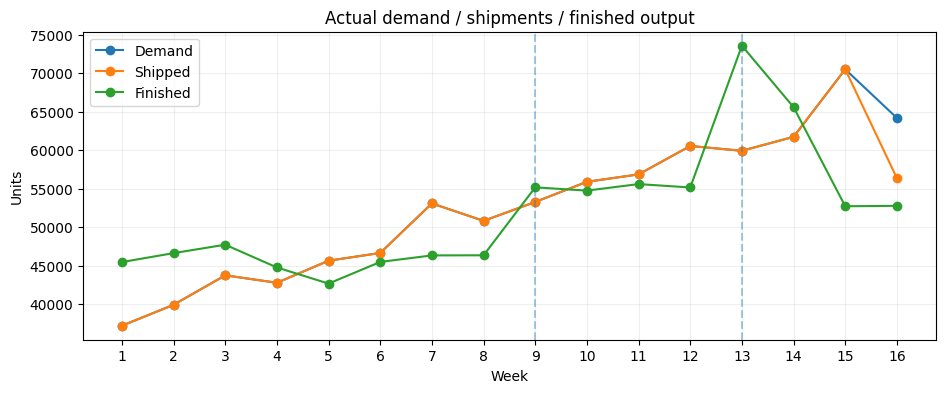

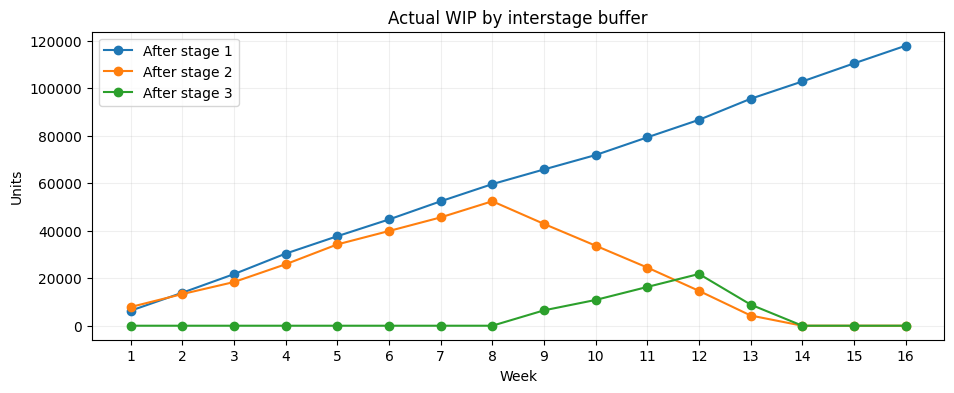

In [4]:
weekly = a.groupby('week_id',as_index=False).agg(demand=('demand_units','sum'), shipped=('shipped_units','sum'), finished=('finished_units','sum'))
fig,ax=plt.subplots(figsize=(11,4))
for col in ['demand','shipped','finished']:
    ax.plot(weekly.week_id,weekly[col],marker='o',label=col.title())
ax.set(xlabel='Week',ylabel='Units',title='Actual demand / shipments / finished output')
ax.axvline(9,ls='--',alpha=.4);ax.axvline(13,ls='--',alpha=.4)
ax.set_xticks(range(1,17));ax.legend();ax.grid(alpha=.2);plt.show()

wip_plot=w.pivot_table(index='week_id',columns='after_stage_id',values='ending_wip_units',aggfunc='sum')
fig,ax=plt.subplots(figsize=(11,4))
for s in [1,2,3]: ax.plot(wip_plot.index,wip_plot[s],marker='o',label=f'After stage {s}')
ax.set(xlabel='Week',ylabel='Units',title='Actual WIP by interstage buffer')
ax.set_xticks(range(1,17));ax.legend();ax.grid(alpha=.2);plt.show()

## 4. Counterfactual multi-period production planning
**Linear Programming, not an operational forecast.** Each machine has a capacity budget based on observed operating minutes × nominal performance. The model conserves product by week and stage, including raw inventory, WIP, FG and backlog. It optimizes all 16 weeks simultaneously and therefore has **perfect hindsight** about the weeks of demand and yield.

The chosen LP objective strongly prioritizes minimizing total backlog across weeks and gives small penalties to holding WIP/FG. The objective is **not total economic profit or a MILP**. The modeled units may be fractional (capacity-planning approximation).

In [5]:
names=['S0 | As-is optimal plan','S1 | OT +10% Cut/Grind','S2 | Performance +5pp','S3 | Add Grinding W9','S4 | OT + New Grinding','S5 | OT + Perf + New Grinding']
# Use generated output files for a fast opening; rerun optimizer for reproducibility below.
summary=pd.read_csv(ROOT/'outputs'/'scenario_summary.csv')
display(summary[['scenario','total_shipped','ending_backlog','fulfilled_pct','total_policy_cost_usd_assumed']].round(2))

,scenario,total_shipped,ending_backlog,fulfilled_pct,total_policy_cost_usd_assumed
0,S0 | As-is optimal plan,838435.86,4469.14,99.47,22345.71
1,S1 | OT +10% Cut/Grind,842905.00,0.00,100.00,1320.87
2,S2 | Performance +5pp,842905.00,0.00,100.00,48000.00
3,S3 | Add Grinding W9,842905.00,0.00,100.00,75000.00
4,S4 | OT + New Grinding,842905.00,0.00,100.00,76103.62
5,S5 | OT + Perf + New Grinding,842905.00,0.00,100.00,124044.22


In [6]:
# Proof of reproducibility: solve just S0, compare to saved results.
base=optimize_16w(tables,data,names[0])
print('Calculated S0 shipment total:',round(base['service'].shipped_units.sum(),2))
print('Saved S0 shipment total:',round(summary.iloc[0].total_shipped,2))
assert abs(base['service'].shipped_units.sum()-summary.iloc[0].total_shipped)<.01

Calculated S0 shipment total: 838435.86
Saved S0 shipment total: 838435.86


## 5. Compare stage/weekly trajectories of each policy
Overtime is authorized up to +10% **only in Cutting & Grinding**, from W9. Performance +5pp begins W9. New Grinding is assumed commissioned at W9, with its capital cost included in post-hoc cost comparison. Existing M0304 and M0404 remain commissioned at actual W9/W13 in every scenario.

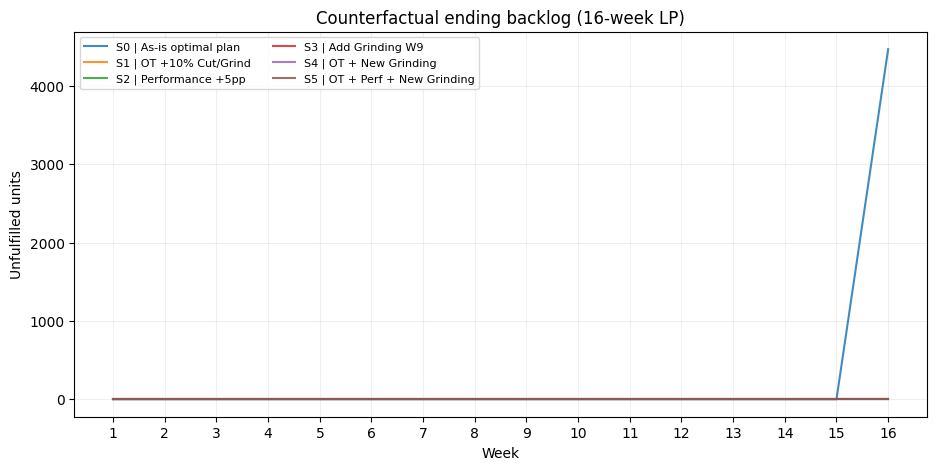

In [7]:
scenarios=pd.read_csv(ROOT/'outputs'/'sim_service.csv')
weekly_scenarios=scenarios.groupby(['scenario','week_id'],as_index=False).ending_backlog_units.sum()
fig,ax=plt.subplots(figsize=(11,5))
for n,g in weekly_scenarios.groupby('scenario',sort=False):
    ax.plot(g.week_id,g.ending_backlog_units,label=n,alpha=.85)
ax.set(xlabel='Week',ylabel='Unfulfilled units',title='Counterfactual ending backlog (16-week LP)')
ax.set_xticks(range(1,17));ax.legend(fontsize=8,ncol=2);ax.grid(alpha=.2);plt.show()

## 6. Economic scoring: illustrative, not audited financials
The LP first maximizes customer service. Then we score candidate policies using explicitly assumed incremental OT labor/energy rates and project/capex. Backlog penalty is **$5 per outstanding unit-week**, a sensitivity assumption rather than a measured contract charge.

A relatively low policy-cost scenario can still be financially poor after including longer-term capital value, preventive maintenance, vendor capacity and future-year demand; do not interpret a 16-week cost comparison as a full equipment ROI.

In [8]:
cols=['scenario','ending_backlog','overtime_cost_usd_assumed','performance_project_cost_usd_assumed','new_machine_cost_usd_assumed','backlog_penalty_usd_assumed','total_policy_cost_usd_assumed']
display(summary[cols].round(1).sort_values('total_policy_cost_usd_assumed'))

,scenario,ending_backlog,overtime_cost_usd_assumed,performance_project_cost_usd_assumed,new_machine_cost_usd_assumed,backlog_penalty_usd_assumed,total_policy_cost_usd_assumed
1,S1 | OT +10% Cut/Grind,0.0,1320.9,0.0,0.0,0.0,1320.9
0,S0 | As-is optimal plan,4469.1,0.0,0.0,0.0,22345.7,22345.7
2,S2 | Performance +5pp,0.0,0.0,48000.0,0.0,0.0,48000.0
3,S3 | Add Grinding W9,0.0,0.0,0.0,75000.0,0.0,75000.0
4,S4 | OT + New Grinding,0.0,1103.6,0.0,75000.0,0.0,76103.6
5,S5 | OT + Perf + New Grinding,0.0,1044.2,48000.0,75000.0,0.0,124044.2


## 7. Stress test — sensitivity, not validated delivery probability
Stress draws perturb W9–W16 demand (~3% typical scale), operating time (~2.5%) and yield (0.15 percentage points). The optimizer re-plans each fully observed shock path, **an optimistic assumption**. The stress test was run separately and stored as CSV to keep this notebook quick.

,scenario,n_trials,mean_ending_backlog,median_ending_backlog,p90_ending_backlog,probability_zero_backlog,mean_demand
0,S0 | As-is optimal plan,150,4376.599,3313.797,10619.064,0.327,842232.308
1,S1 | OT +10% Cut/Grind,150,0.000,0.000,0.000,1.000,842232.308
2,S2 | Performance +5pp,150,0.000,0.000,0.000,1.000,842232.308
3,S3 | Add Grinding W9,150,0.000,0.000,0.000,1.000,842232.308


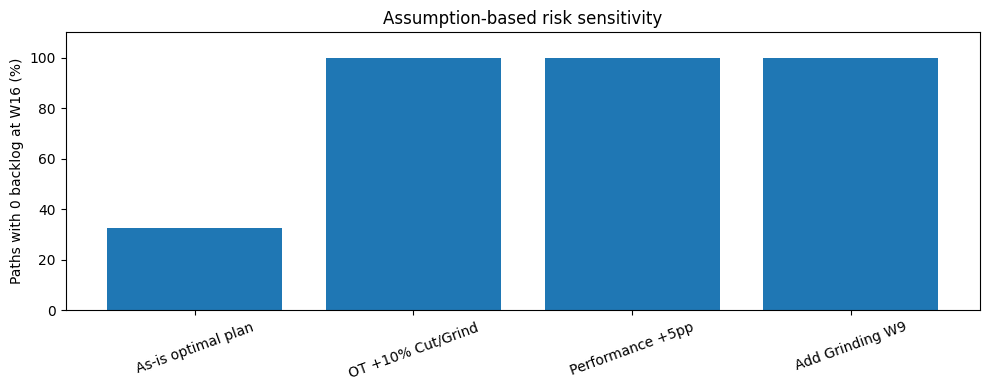

In [9]:
stress=pd.read_csv(ROOT/'outputs'/'stress_summary.csv')
display(stress.round(3))
fig,ax=plt.subplots(figsize=(10,4))
ax.bar(stress.scenario.str.split('|').str[-1].str.strip(),100*stress.probability_zero_backlog)
ax.set(ylabel='Paths with 0 backlog at W16 (%)',title='Assumption-based risk sensitivity')
ax.set_ylim(0,110);ax.tick_params(axis='x',rotation=20);plt.tight_layout();plt.show()

## 8. Dashboard and Power BI
- Open `outputs/dashboard.html` in a browser for the completed interactive dashboard.
- Import the `outputs/*.csv` tables into Power BI Desktop and follow `powerbi/README_POWERBI.md`.
- Add DAX measures individually from `powerbi/MEASURES.dax`.

## Project limitations to state in an Apple CV/portfolio
1. Source data are synthetic and not Apple supplier operations.
2. Counterfactual simulations condition on realized future outcomes (look-ahead bias). A genuine prospective model would train forecasts only on data available at each decision date and evaluate on held-out weeks.
3. Nominal performance and cycle times are approximations; detailed job scheduling and physical WIP transfer lead time are not simulated.
4. FG snapshots have a source inconsistency; reconciled ledger takes precedence.
5. Scenarios are compared by post-hoc illustrative costs rather than globally optimized investment MILP.

**Recommended follow-up experiment:** rolling-horizon backtest or prospective weeks 17–24 demand forecast, with decision lead times and forecast uncertainty.


## 9. Optional forward planning for W17–W24 — the actionable decision horizon

**This section is not a retrospective simulation.** We use only W1–W16 actual data to project future demand and capacity. Demand is extrapolated with a simple linear trend using W9–W16 for each product; machine availability and yield are estimated from W13–W16. Opening W17 raw inventory, WIP and backlog come from the reconciled W16 actual. The projected horizon has **no observed actual outcomes yet**.

The new Grinding machine (and optional new Cutting machine) is purchased in hypothetical W17 and commissioned in W20 after a three-week lead. This is a *scenario*, not a procurement recommendation. The unvalidated demand extrapolation makes the results uncertain.

In [10]:
forecast=pd.read_csv(ROOT/'outputs'/'forward_demand_forecast_W17_W24.csv')
future_summary=pd.read_csv(ROOT/'outputs'/'forward_scenario_summary_W17_W24.csv')
future_capacity=pd.read_csv(ROOT/'outputs'/'forward_capacity_W17_W24.csv')
print('Forecast new demand W17-W24:',round(forecast.forecast_demand_units.sum()))
print('Opening backlog W17:',int(future_summary.opening_backlog_w17.iloc[0]))
display(future_summary[['scenario','forecast_horizon_shipped','ending_backlog_w24','fulfillment_total_requirement_pct','new_machine_capex_usd_assumed']].round(1))
load=future_capacity.query('week_id==24 and scenario=="F3 | OT + Add Grinding W20"').groupby('stage_id')[['ideal_workload_minutes','effective_capacity_minutes']].sum()
load['utilization_pct']=100*load.ideal_workload_minutes/load.effective_capacity_minutes
display(load.round(1))

Forecast new demand W17-W24: 607573
Opening backlog W17: 7816


,scenario,forecast_horizon_shipped,ending_backlog_w24,fulfillment_total_requirement_pct,new_machine_capex_usd_assumed
0,F0 | Existing capacity,420007.2,195382.0,68.3,0.0
1,F1 | OT +10% Cut/Grind,461902.1,153487.1,75.1,0.0
2,F2 | Add Grinding W20,465588.5,149800.6,75.7,75000.0
3,F3 | OT + Add Grinding W20,481298.6,134090.5,78.2,75000.0
4,F4 | Add Grinding + Cutting W20,465588.5,149800.6,75.7,142000.0
5,F5 | OT + Both new machines,481298.6,134090.5,78.2,142000.0


,ideal_workload_minutes,effective_capacity_minutes,utilization_pct
stage_id,,,
1,16459.1,17488.2,94.1
2,23936.1,27522.3,87.0
3,20377.8,20377.8,100.0
4,17445.9,20857.6,83.6


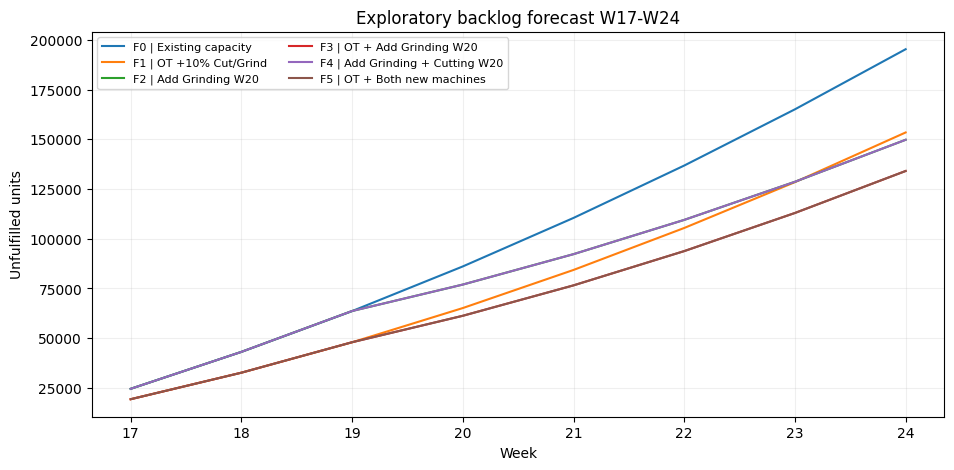

In [11]:
forward_service=pd.read_csv(ROOT/'outputs'/'forward_service_W17_W24.csv')
future_week=forward_service.groupby(['scenario','week_id'],as_index=False).ending_backlog_units.sum()
fig,ax=plt.subplots(figsize=(11,5))
for name,group in future_week.groupby('scenario',sort=False):
    ax.plot(group.week_id,group.ending_backlog_units,label=name)
ax.set(title='Exploratory backlog forecast W17-W24',xlabel='Week',ylabel='Unfulfilled units')
ax.set_xticks(range(17,25));ax.grid(alpha=.2)
ax.legend(fontsize=8,ncol=2);plt.show()